<a href="https://colab.research.google.com/github/Meghakoranga/OnlineRetailAnalysis/blob/main/OnlineRetailAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
!pip install ucimlrepo

In [28]:
from ucimlrepo import fetch_ucirepo
online_retail=fetch_ucirepo(id=352)
df=online_retail.data.original

In [29]:
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [30]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [31]:
print(online_retail.variables[["name","role","type","description"]])

          name     role         type  \
0    InvoiceNo       ID  Categorical   
1    StockCode       ID  Categorical   
2  Description  Feature  Categorical   
3     Quantity  Feature      Integer   
4  InvoiceDate  Feature         Date   
5    UnitPrice  Feature   Continuous   
6   CustomerID  Feature  Categorical   
7      Country  Feature  Categorical   

                                         description  
0  a 6-digit integral number uniquely assigned to...  
1  a 5-digit integral number uniquely assigned to...  
2                                       product name  
3  the quantities of each product (item) per tran...  
4  the day and time when each transaction was gen...  
5                             product price per unit  
6  a 5-digit integral number uniquely assigned to...  
7  the name of the country where each customer re...  


In [32]:
df_raw=df.copy()  #backup

In [33]:
print("dataset shape:",df.shape)
df.head()
df.info()
df.describe(include="all")

dataset shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [34]:
missing_values=df.isnull().sum()
print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [35]:
duplicate_count=df.duplicated().sum()
print("duplicate rows:",duplicate_count)


duplicate rows: 5268


In [36]:
df=df.drop_duplicates().copy()
print("shape after removing duplicates :", df.shape)

shape after removing duplicates : (536641, 8)


In [37]:
cancellations=df[df["InvoiceNo"].astype(str).str.startswith("C")].copy()
print("Cancellation records:",len(cancellations))

Cancellation records: 9251


In [39]:
sales=df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [40]:
sales=sales[(sales["Quantity"]>0)&(sales["UnitPrice"]>0)].copy()

In [41]:
df_clean = sales.dropna(subset=["Description"]).copy()

In [42]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

In [43]:
customer_data = df_clean.dropna(
    subset=["CustomerID"]
).copy()

In [44]:
print("\nOriginal shape:", df_raw.shape)
print("Cleaned sales shape:", df_clean.shape)
print("Customer data shape:", customer_data.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining duplicates:", df_clean.duplicated().sum())


Original shape: (541909, 8)
Cleaned sales shape: (524878, 8)
Customer data shape: (392692, 8)

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64

Remaining duplicates: 0


In [45]:
df_clean.to_csv("Online_Retail_Cleaned.csv",index=False)

In [46]:
# Module 2 : Expolaratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
df_clean["Revenue"]=(df_clean["Quantity"]* df_clean["UnitPrice"])
df_clean[["Description","Quantity","UnitPrice","Revenue"]].head()

,Description,Quantity,UnitPrice,Revenue
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,WHITE METAL LANTERN,6,3.39,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [57]:
print("total Revenue:",df_clean["Revenue"].sum())

total Revenue: 10642110.804000001



Monthly Revenue:
      Month      Revenue
0   2010-12   821452.730
1   2011-01   689811.610
2   2011-02   522545.560
3   2011-03   716215.260
4   2011-04   536968.491
5   2011-05   769296.610
6   2011-06   760547.010
7   2011-07   718076.121
8   2011-08   757841.380
9   2011-09  1056435.192
10  2011-10  1151263.730
11  2011-11  1503866.780
12  2011-12   637790.330


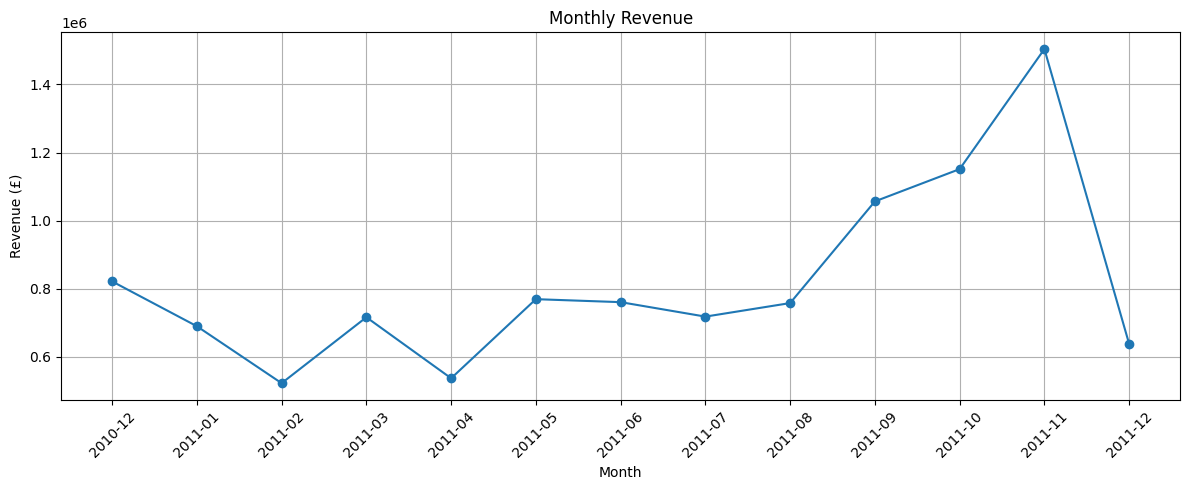

In [67]:
df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

print("\nMonthly Revenue:")
print(monthly_revenue)
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["Month"].astype(str),
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()


Top 10 Products by Quantity:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


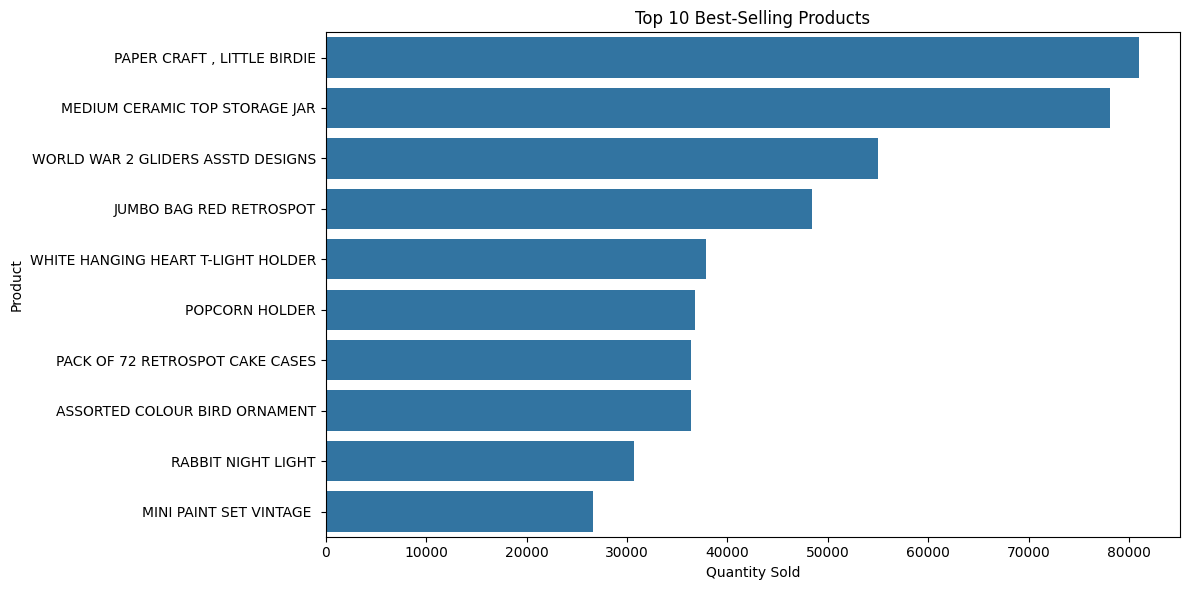

In [70]:
# top selling products
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print("\nTop 10 Products by Quantity:")
print(top_products)
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

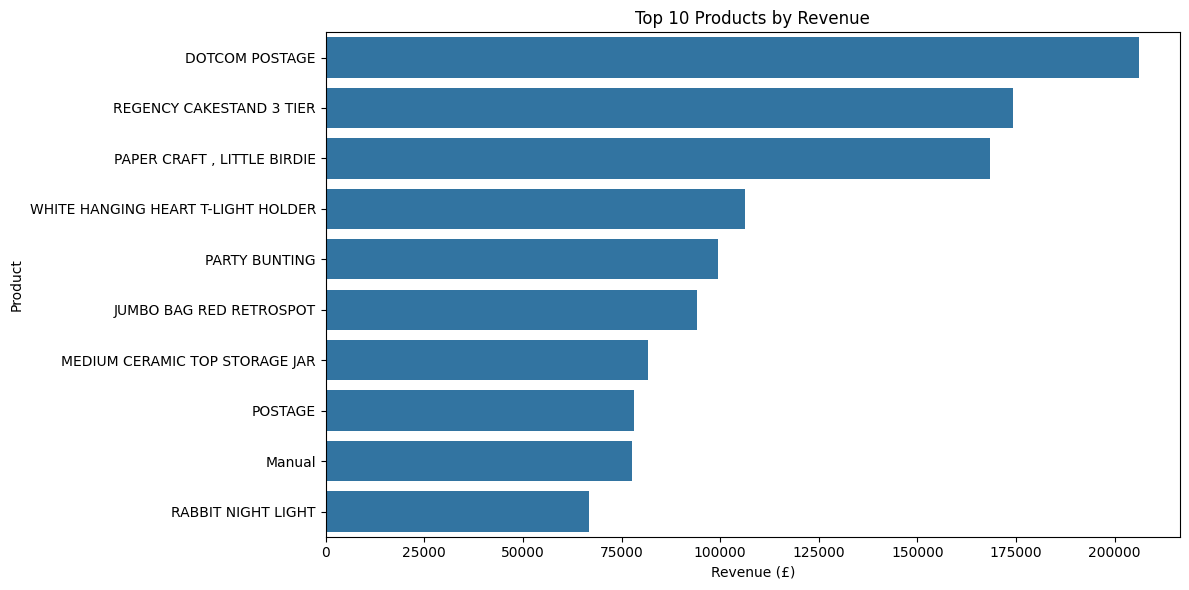

In [71]:
# Top 10 Products by Revenue

top_revenue_products = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_revenue_products.values,
    y=top_revenue_products.index
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()



Customer Purchase Frequency:
   CustomerID  PurchaseFrequency
0     12346.0                  1
1     12347.0                  7
2     12348.0                  4
3     12349.0                  1
4     12350.0                  1
5     12352.0                  8
6     12353.0                  1
7     12354.0                  1
8     12355.0                  1
9     12356.0                  3


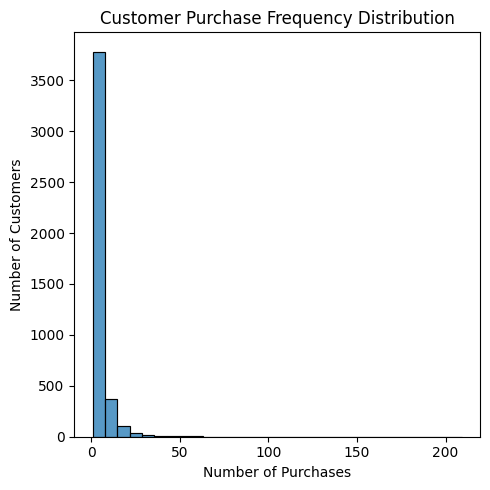

In [75]:
#customer purchase frequency
purchase_frequency = (
    customer_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index()
)

purchase_frequency.columns = [
    "CustomerID",
    "PurchaseFrequency"
]

print("\nCustomer Purchase Frequency:")
print(purchase_frequency.head(10))

plt.figure(figsize=(5, 5))

sns.histplot(
    data=purchase_frequency,
    x="PurchaseFrequency",
    bins=30
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


Revenue by Country:
          Country      Revenue
0  United Kingdom  9001744.094
1     Netherlands   285446.340
2            EIRE   283140.520
3         Germany   228678.400
4          France   209625.370
5       Australia   138453.810
6           Spain    61558.560
7     Switzerland    57067.600
8         Belgium    41196.340
9          Sweden    38367.830


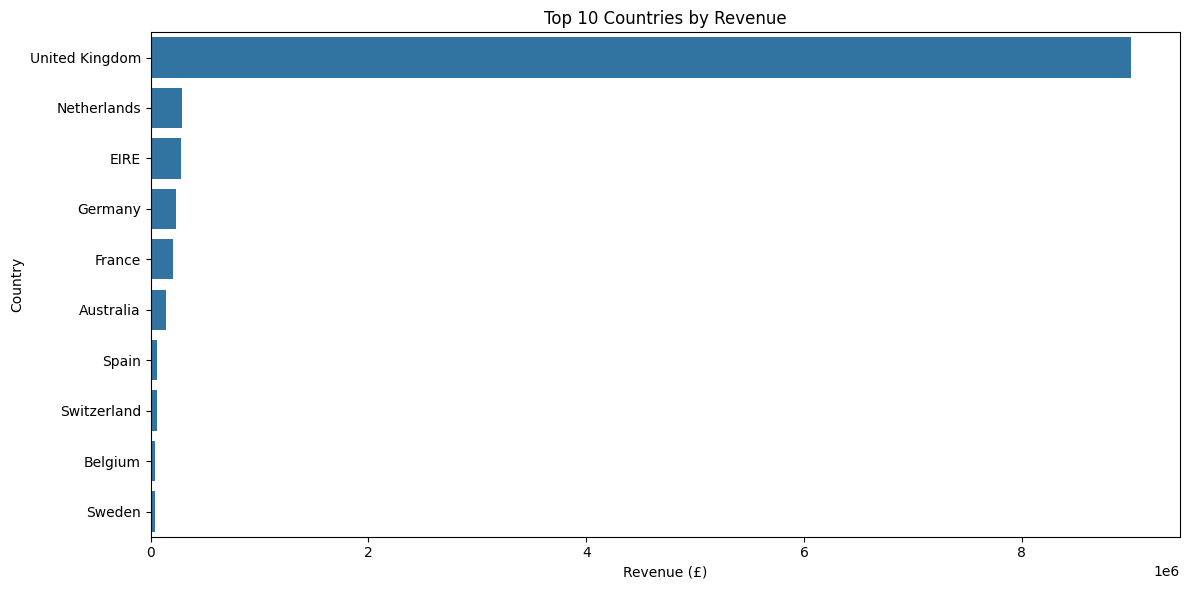

In [76]:
#Revenue by Country
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\nRevenue by Country:")
print(country_revenue.head(10))

top_countries = country_revenue.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [78]:
monthly_revenue.to_csv(
    "Monthly_Revenue.csv", index=False
)
purchase_frequency.to_csv(
    "Purchase_Frequency.csv", index=False
)
country_revenue.to_csv(
    "Country_Revenue.csv", index=False
)